# Do late deliveries hurt review scores?
Statistical test of the Q3 finding from the SQL analysis, using Olist delivered orders.

In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
conn = sqlite3.connect("olist.db")

query = """
SELECT r.review_score,
       CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date)
            THEN 'late' ELSE 'on time' END AS delivery_status
FROM orders o
JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
"""

df = pd.read_sql(query, conn)
df.head()

,review_score,delivery_status
0,4,on time
1,4,on time
2,5,on time
3,5,on time
4,5,on time


In [4]:
df.groupby("delivery_status")["review_score"].agg(["count", "mean", "std"]).round(2)

,count,mean,std
delivery_status,,,
late,6409,2.27,1.57
on time,89944,4.29,1.15


In [5]:
on_time = df.loc[df["delivery_status"] == "on time", "review_score"]
late    = df.loc[df["delivery_status"] == "late", "review_score"]

t_stat, p_value = stats.ttest_ind(on_time, late, equal_var=False)
print(f"t = {t_stat:.1f}, p = {p_value:.2e}")

# Effect size (Cohen's d): how BIG the gap is, not just whether it's real
pooled_sd = ((on_time.var() + late.var()) / 2) ** 0.5
cohens_d = (on_time.mean() - late.mean()) / pooled_sd
print(f"Cohen's d = {cohens_d:.2f}")

t = 101.0, p = 0.00e+00
Cohen's d = 1.47


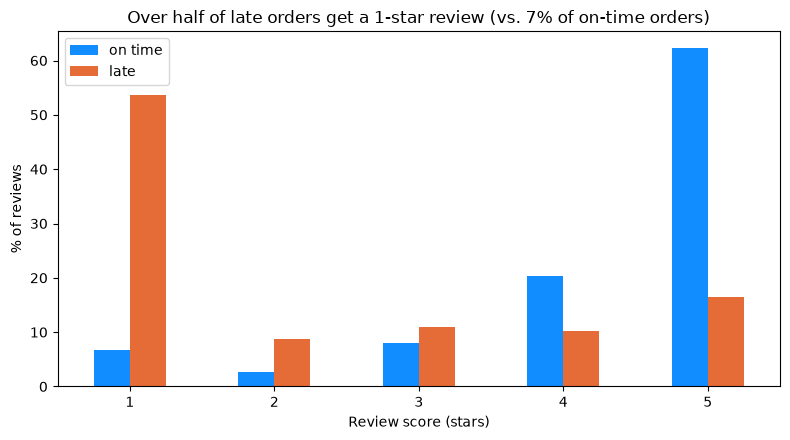

In [7]:
dist = (df.groupby("delivery_status")["review_score"]
          .value_counts(normalize=True)
          .mul(100)
          .unstack(0))

ax = dist[["on time", "late"]].plot(kind="bar", color=["#118DFF", "#E66C37"],
                                     figsize=(8, 4.5), rot=0)
ax.set_title("Over half of late orders get a 1-star review (vs. 7% of on-time orders)")
ax.set_xlabel("Review score (stars)")
ax.set_ylabel("% of reviews")
ax.legend(title="")
plt.tight_layout()
plt.savefig("review_distribution.png", dpi=150)
plt.show()

## Conclusion
- On-time orders average **4.29 stars** (n = 89,944 reviews); late orders average **2.27** (n = 6,409).
- **Welch's t-test:** t = 101.0, p < 0.001. The gap is not due to chance.
- **Cohen's d = 1.47:** a very large effect (≥ 0.8 is considered large).
- **54% of late-order reviews are 1-star**, vs. 7% for on-time orders, about 8x more likely.
- **Caveat:** this is observational data. Late orders may differ in other ways (region,
  product type), so it shows a strong association rather than proof of cause.